In [2]:
import io
import pandas as pd

# 1. Carichiamo i tuoi dati (simulando la lettura di un file CSV)
# dati_csv = """Nome edificio,Città,Stato,Anno,Piani,Altezza
# Petronas Tower 1, Kuala Lumpur,Malaysia,1998.0,88.0,452.0
# Sears Tower, Chicago,USA,1974.0,110.0,442.0
# Jin Mao Building, Shanghai,Cina,1999.0,88.0,421.0
# ... [tutti gli altri dati] ...
# Bank of America Plaza, Dallas,USA,1985.0,72.0,281.0"""

#FONDAMENTALE PER AVERE UNA CORRETTA VISIONE DEI RISULTATI
# 1. Rimuoviamo i limiti di visualizzazione delle colonne in Jupyter
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Se avessi un file reale useresti: df = pd.read_csv('grattacieli.csv')
#df = pd.read_csv(io.StringIO(dati_csv))
#df sta per dataFrame
df = pd.read_csv("C:\\Users\\io\\Desktop\\Argomenti\\Claude\\panda\\dati\\Edifici.csv", sep=';', decimal=',')

# Pulizia rapida degli spazi vuoti nei nomi delle colonne e nei testi
df.columns = df.columns.str.strip()
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

print("--- DATI CARICATI CON SUCCESSO ---\n")

print(df)

--- DATI CARICATI CON SUCCESSO ---

                      Nome edificio         Città           Stato  Anno  Piani  Altezza
0                  Petronas Tower 1  Kuala Lumpur        Malaysia  1998     88      452
1                       Sears Tower       Chicago             USA  1974    110      442
2                  Jin Mao Building      Shanghai            Cina  1999     88      421
3                       Citic Plaza     Guangzhou            Cina  1996     80      391
4                  Shun Hing Square      Shenzhen            Cina  1996     69      384
5             Empire State Building      New York             USA  1931    102      381
6                     Central Plaza     Hong Kong           Corea  1992     78      374
7               Bank of China Tower     Hong Kong           Corea  1989     70      369
8                Emirates Tower One         Dubai           Dubai  1999     55      355
9                        The Center     Hong Kong           Corea  1998     79      

In [15]:
conteggio=df.agg({"Città": ["count"], "Altezza": ["mean"]})
print(conteggio) #40 40

       Città  Altezza
count   40.0      NaN
mean     NaN   325.25


In [16]:
#conta tutto in base alla colonna città
groupByCitta=df.groupby(["Città"]).count()
print(groupByCitta)

              Nome edificio  Stato  Anno  Piani  Altezza
Città                                                   
Atlanta                   1      1     1      1        1
Bangkok                   1      1     1      1        1
Chicago                   6      6     6      6        6
Cleveland                 1      1     1      1        1
Dallas                    1      1     1      1        1
Dubai                     3      3     3      3        3
Francoforte               1      1     1      1        1
Guangzhou                 1      1     1      1        1
Hong Kong                 4      4     4      4        4
Houston                   2      2     2      2        2
Kaohsiung                 1      1     1      1        1
Kuala Lumpur              2      2     2      2        2
Los Angeles               1      1     1      1        1
New York                  4      4     4      4        4
Philadelphia              1      1     1      1        1
Pyongyang                 1    

In [17]:

#conta tutto in base alla colonna Stato
bho=df.groupby(["Stato"]).count()
print(bho) 

                Nome edificio  Città  Anno  Piani  Altezza
Stato                                                     
Arabia Saudita              1      1     1      1        1
Canada                      1      1     1      1        1
Cina                        7      7     7      7        7
Corea                       5      5     5      5        5
Dubai                       3      3     3      3        3
Germania                    1      1     1      1        1
Giappone                    1      1     1      1        1
Malaysia                    2      2     2      2        2
Tailandia                   1      1     1      1        1
Taiwan                      1      1     1      1        1
USA                        17     17    17     17       17


In [ ]:
# 2. Vedere i primi 5 grattacieli della lista
print("I primi 5 edifici:")
print(df.head(), "\n")

In [ ]:

# 3. Trovare l'altezza media, massima e minima
altezza_massima = df["Altezza"].max()
altezza_media = df["Altezza"].mean()
altezza_min = df["Altezza"].min()
print(f"Altezza massima: {altezza_massima} metri")
print(f"Altezza media: {altezza_media:.2f} metri\n")
print(f"Altezza Minima: {altezza_min:.2f} metri\n")

In [ ]:
# 4. Filtrare: Trovare tutti i grattacieli negli USA con più di 80 piani
grattacieli_usa_grandi = df[(df["Stato"] == "USA") & (df["Piani"] > 80)]
print("Edifici negli USA con più di 80 piani:")
print(grattacieli_usa_grandi[["Nome edificio", "Città", "Piani"]], "\n")

In [ ]:
# 5. Raggruppare: Quanti grattacieli ci sono in lista per ogni Stato?
conteggio_stati = df["Stato"].value_counts()
print("Numero di grattacieli per Stato nella lista:")
print(conteggio_stati, "\n")

In [34]:
# 6. Raggruppare: Quanti grattacieli ci sono in lista per ogni Città?
conteggio_stati = df["Città"].value_counts()
print("Numero di grattacieli per città nella lista:")
print(conteggio_stati, "\n")


Numero di grattacieli per città nella lista:
Città
Chicago         6
Hong Kong       4
New York        4
Shanghai        3
Dubai           3
Kuala Lumpur    2
Houston         2
Shenzhen        2
Kaohsiung       1
Atlanta         1
Los Angeles     1
Guangzhou       1
Bangkok         1
Pyongyang       1
Francoforte     1
Toronto         1
Riyadh          1
Yokohama        1
Seattle         1
Cleveland       1
Philadelphia    1
Dallas          1
Name: count, dtype: int64 



In [ ]:
# Conta le righe per ogni città e trasforma il risultato in un DataFrame pulito
risultato = df.groupby('Città').size().reset_index(name='Conteggio').sort_values(
    by=['Conteggio', 'Città'], 
    ascending=[False, True]
).reset_index(drop=True) # <-- Questo resetta i numeri da 0 in poi

print(risultato)

In [ ]:
#Media altezza per città
media = df.groupby('Città')['Altezza'].mean().reset_index(name='Media').sort_values(
    by=['Media', 'Città'], 
    ascending=[False, True]
).reset_index(drop=True)

print(media)

In [81]:
#Edificio più alto
max_altezza = df["Altezza"].max()
print("Grattacielo più alto:")
print(max_altezza, "\n")


#con visualizzazione della città
CittaAltezza = df.groupby('Città')['Altezza'].max().reset_index(name='Massimo').sort_values(
    by=['Massimo', 'Città'], 
    ascending=[False, True]
).reset_index(drop=True).head(1)

print(CittaAltezza)

Grattacielo più alto:
452 

          Città  Massimo
0  Kuala Lumpur      452


In [73]:
# Uniamo le due tabelle usando la colonna 'Città' come chiave
tabella_finale = pd.merge(risultato, media, on='Città', how='inner')

# Opzionale: arrotondiamo la media a due cifre decimali per renderla più leggibile
tabella_finale['Media'] = tabella_finale['Media'].round(2)

print(tabella_finale)

           Città  Conteggio   Media
0        Chicago          6  339.17
1      Hong Kong          4  345.75
2       New York          4  318.25
3          Dubai          3  328.33
4       Shanghai          3  329.00
5        Houston          2  300.50
6   Kuala Lumpur          2  381.00
7       Shenzhen          2  338.00
8        Atlanta          1  312.00
9        Bangkok          1  304.00
10     Cleveland          1  290.00
11        Dallas          1  281.00
12   Francoforte          1  299.00
13     Guangzhou          1  391.00
14     Kaohsiung          1  348.00
15   Los Angeles          1  310.00
16  Philadelphia          1  288.00
17     Pyongyang          1  300.00
18        Riyadh          1  296.00
19       Seattle          1  295.00
20       Toronto          1  298.00
21      Yokohama          1  296.00


In [76]:
#tutto in un comando solo con agg
# Raggruppa per città e applica il conteggio (size) su una colonna e la media (mean) sull'altezza
tabella_veloce = df.groupby('Città').agg(
    Conteggio=('Nome edificio', 'size'),
    Media=('Altezza', 'mean')
).reset_index()

# Arrotonda e ordina
tabella_veloce['Media'] = tabella_veloce['Media'].round(2)
tabella_veloce = tabella_veloce.sort_values(by=['Conteggio', 'Città'], ascending=[False, True]).reset_index(drop=True)

print(tabella_veloce)


           Città  Conteggio   Media
0        Chicago          6  339.17
1      Hong Kong          4  345.75
2       New York          4  318.25
3          Dubai          3  328.33
4       Shanghai          3  329.00
5        Houston          2  300.50
6   Kuala Lumpur          2  381.00
7       Shenzhen          2  338.00
8        Atlanta          1  312.00
9        Bangkok          1  304.00
10     Cleveland          1  290.00
11        Dallas          1  281.00
12   Francoforte          1  299.00
13     Guangzhou          1  391.00
14     Kaohsiung          1  348.00
15   Los Angeles          1  310.00
16  Philadelphia          1  288.00
17     Pyongyang          1  300.00
18        Riyadh          1  296.00
19       Seattle          1  295.00
20       Toronto          1  298.00
21      Yokohama          1  296.00


In [ ]:
# 7. Ordinare i dati: I 3 edifici più vecchi ancora in lista
piu_vecchi = df.sort_values(by="Anno").head(3)
print("I 3 grattacieli più storici della lista:")
print(piu_vecchi[["Nome edificio", "Anno", "Città","Stato"]])


I 3 grattacieli più storici della lista:
            Nome edificio  Anno     Città Stato
37         40 Wall Street  1930  New York   USA
14      Chrysler Building  1930  New York   USA
5   Empire State Building  1931  New York   USA


In [ ]:
#altezza media per stato
df.groupby('Stato')['Altezza'].mean().reset_index()


,Stato,Altezza
0,Arabia Saudita,296.000000
1,Canada,298.000000
2,Cina,334.857143
3,Corea,336.600000
4,Dubai,328.333333
5,Germania,299.000000
6,Giappone,296.000000
7,Malaysia,381.000000
8,Tailandia,304.000000
9,Taiwan,348.000000


In [ ]:
#Modalità corrette:

#edificio più alto
piuAlto=df[df['Altezza'] == df['Altezza'].max()]
print("Edificio più alto:\n",piuAlto,"\n")

#edificio più basso
piuBasso=df[df['Altezza'] == df['Altezza'].min()]
print("Edificio più basso:\n",piuBasso,"\n")

#Altezza media
altezzaMedia=df['Altezza'].mean()
print(f"Altezza media: {altezzaMedia:.2f}\n")

#edificio più vecchio
piuVecchio=df[df['Anno'] == df['Anno'].min()]
print("Edificio più vecchio:\n",piuVecchio,"\n")

#edificio più nuovo
piuNuovo=df[df['Anno'] == df['Anno'].max()]
print("Edificio più nuovo:\n",piuNuovo,"\n")

#edifici totali
conteggio_edifici = df["Nome edificio"].count()
print("Edifici_totali:",conteggio_edifici, "\n")

#edifici totali per stato
conteggio_edifici = df["Stato"].value_counts()
print("Edifici_totali per stato:\n",conteggio_edifici, "\n")

#edifici negli usa
edifici_usa = df[(df["Stato"] == "USA")]
print("edifici_usa:\n",edifici_usa, "\n")

#edifici costruiti tra il 1930 e il 1970 compresi
edifici_tra_2_date=df[(df["Anno"] >= 1930) & (df["Anno"] <= 1970)]
print("edifici_tra_2_date:\n",edifici_tra_2_date)

#Ancora meglio usando between
# Equivalente esatto di prima (include gli estremi 1930 e 1970)
edifici_tra_2_date = df[df["Anno"].between(1930, 1970)]
print("edifici_tra_2_date:\n",edifici_tra_2_date)

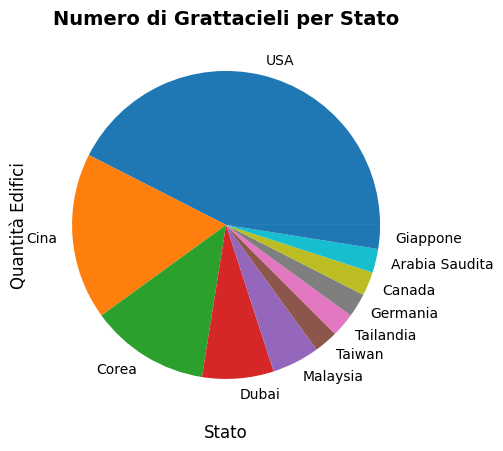

In [ ]:
# Grafici:
# 1. Calcoliamo il conteggio degli edifici per Stato
conteggio_stati = df["Stato"].value_counts()

# 2. Generiamo il grafico a barre direttamente da Pandas
conteggio_stati.plot(
    kind='bar', #pie         # Tipo di grafico: 'bar' per barre verticali
    figsize=(10, 5),     # Dimensioni della figura (larghezza, altezza)
    color='skyblue',     # Colore delle barre
    edgecolor='black'    # Colore del bordo delle barre -> NO PER GRAFICO PIE!
)

# 3. Aggiungiamo i testi per renderlo leggibile
import matplotlib.pyplot as plt
plt.title("Numero di Grattacieli per Stato", fontsize=14, fontweight='bold')
plt.xlabel("Stato", fontsize=12)
plt.ylabel("Quantità Edifici", fontsize=12)
plt.xticks(rotation=45) # Ruota i nomi degli Stati a 45 gradi per non farli sovrapporre
plt.grid(axis='y', linestyle='--', alpha=0.7) # Aggiunge una griglia leggera sullo sfondo

# 4. Mostriamo il grafico
plt.show()


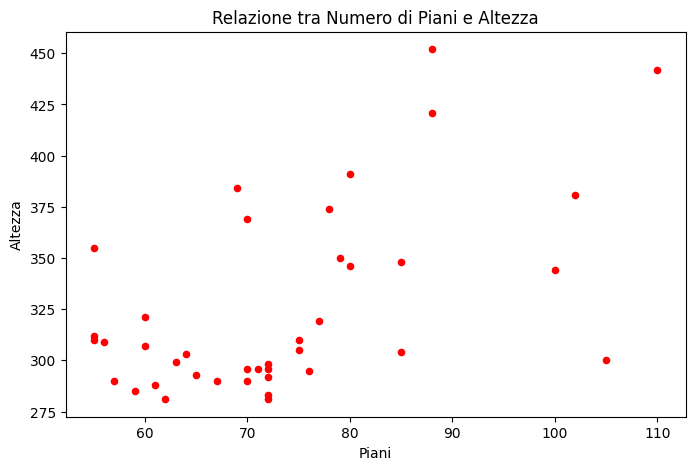

In [70]:
#Grafico a dispersione (Scatter Plot) 
#Per mettere in relazione due numeri (ad esempio per vedere se i grattacieli con più Piani sono anche quelli con maggiore Altezza)
df.plot(
    kind='scatter', 
    x='Piani', 
    y='Altezza', 
    color='red', 
    figsize=(8, 5),
    title="Relazione tra Numero di Piani e Altezza"
)
plt.show()


In [71]:
# Calcoliamo l'altezza media per piano di ogni singolo edificio
df['Altezza_Per_Piano'] = df['Altezza'] / df['Piani']

# Vediamo i dettagli ordinati per questa nuova metrica
print(df[['Nome edificio', 'Città', 'Piani', 'Altezza', 'Altezza_Per_Piano']].sort_values(by='Altezza_Per_Piano', ascending=False).head(5))


                    Nome edificio         Città  Piani  Altezza  Altezza_Per_Piano
8              Emirates Tower One         Dubai     55      355           6.454545
15          Bank of America Plaza       Atlanta     55      312           5.672727
17  Telekom Malaysia Headquarters  Kuala Lumpur     55      310           5.636364
4                Shun Hing Square      Shenzhen     69      384           5.565217
18             Emirates Tower Two         Dubai     56      309           5.517857


In [72]:
# Esportiamo la tabella finale ordinata per l'altezza del singolo piano
df_ordinato = df.sort_values(by='Altezza_Per_Piano', ascending=False)

# Salviamo in Excel (arrotando i decimali a 2 cifre per renderlo pulito)
df_ordinato['Altezza_Per_Piano'] = df_ordinato['Altezza_Per_Piano'].round(2)
df_ordinato.to_excel('Report_Grattacieli_Analisi.xlsx', index=False)

print("File Excel generato con successo!")


File Excel generato con successo!


In [ ]:
#• Scoprire come pulire dati più "sporchi" (con valori mancanti o formati di testo strani)
#• Imparare a gestire le date e il tempo con Pandas
#• Approfondire la creazione di grafici ancora più avanzati